# Minimal forest manifold example

This notebook shows the same workflow twice: once for a sparse-proximity Random Forest, and once for a sparse-proximity Rotation Forest. Each model is fit on `datasets/treeData.csv`, turned into a PHATE embedding, and plotted in 2D.

In [5]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from aeon.classification.sklearn import RotationForestClassifier

from forestgap import Proximity, embed

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "datasets" / "treeData.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

phate_kwargs = {
    "n_components": 2,
    "knn": 15,
    "t": "auto",
    "n_landmark": 300,
    "beta": 0.9,
    "verbose": 0,
}

plt.style.use("default")
pd.set_option("display.max_columns", 10)

print(f"Project root: {PROJECT_ROOT}")

Project root: /yunity/rhodes8/ObliqueProximities/ObliqueProximitiesCode


In [6]:
data_path = PROJECT_ROOT / "datasets" / "treeData.csv"
tree_data = pd.read_csv(data_path)

X = tree_data.drop(columns="branch")
y = tree_data["branch"].astype(int)

print(f"Loaded {data_path.relative_to(PROJECT_ROOT)}")
print(f"X shape: {X.shape}")
print("Branch counts:")
print(y.value_counts().sort_index().to_string())

Loaded datasets/treeData.csv
X shape: (1440, 60)
Branch counts:
branch
1     180
2     140
3     140
4     140
5     140
6     140
7     140
8     140
9     140
10    140


## Random Forest

    SGD-MDS may not have converged: stress changed by 2.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.


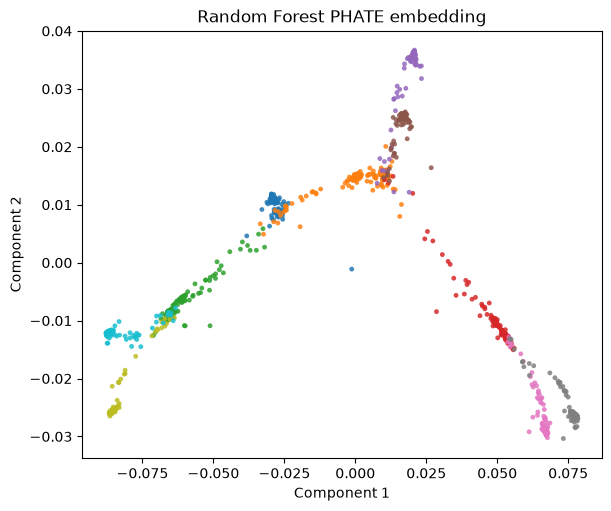

In [7]:
rf_forest = RandomForestClassifier(
    n_estimators=120,
    random_state=42,
    bootstrap=True,
    n_jobs=-1,
 )
rf_proximity = Proximity(
    rf_forest,
    relation="rfgap",
    matrix_type="sparse",
    non_zero_diagonal=True,
 ).fit(X, y)

rf_embedding = embed(rf_proximity, method="phate", **phate_kwargs)

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
cmap = plt.get_cmap("tab10", len(np.unique(y)))
ax.scatter(
    rf_embedding[:, 0],
    rf_embedding[:, 1],
    c=y,
    cmap=cmap,
    s=12,
    alpha=0.85,
    linewidths=0,
 )
ax.set_title("Random Forest PHATE embedding")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
plt.show()

## Rotation Forest

    SGD-MDS may not have converged: stress changed by 2.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.


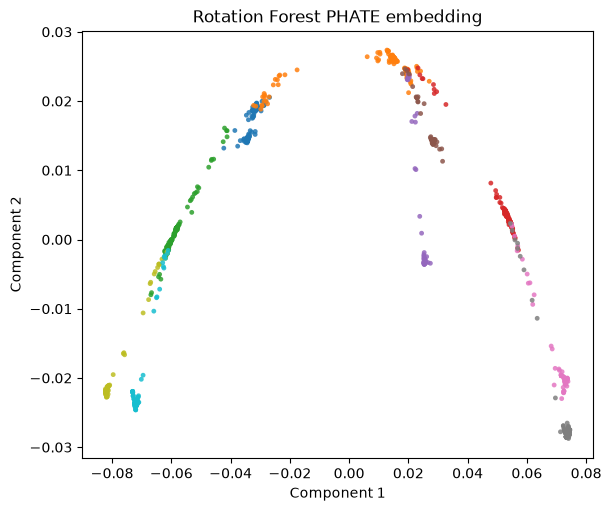

In [8]:
rot_forest = RotationForestClassifier(
    n_estimators=80,
    random_state=42,
    n_jobs=-1,
 )
rot_proximity = Proximity(
    rot_forest,
    relation="rfgap",
    matrix_type="sparse",
    non_zero_diagonal=True,
 ).fit(X, y)

rot_embedding = embed(rot_proximity, method="phate", **phate_kwargs)

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
cmap = plt.get_cmap("tab10", len(np.unique(y)))
ax.scatter(
    rot_embedding[:, 0],
    rot_embedding[:, 1],
    c=y,
    cmap=cmap,
    s=12,
    alpha=0.85,
    linewidths=0,
 )
ax.set_title("Rotation Forest PHATE embedding")
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
plt.show()